# Label correction, Step 1: 
# Majority method for identical texts

# preparing

In [1]:
import duckdb, pandas as pd
from digikala_review_transformer.config import ROOT, DATA_PROCESSED, REPORTS, SPLIT_SEED, DB_PATH, CLEAN_TABLE

con = duckdb.connect(str(DB_PATH))
con.execute("LOAD ui;")
con.execute("CALL start_ui();")

Opening in existing browser session.


[1:1:0100/000000.599743:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)
[12300:12300:0100/000000.601907:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)


In [2]:
import shutil
from digikala_review_transformer.config import DATA_INTERIM

cur = con.cursor()

def scalar(query, params=None):
    # fetchall() fully consumes the result, so nothing stays open
    return cur.execute(query, params or []).fetchall()[0][0]

print(cur.sql("SHOW TABLES").df())
print(cur.sql(f"DESCRIBE {CLEAN_TABLE}").df())

# Check the DB size and free disk space before writing a backup
print("DB size (GB):", round(DB_PATH.stat().st_size / 1e9, 2))
print("Free disk (GB):", round(shutil.disk_usage(ROOT).free / 1e9, 2))

                 name
0   body_backup_latin
1          clean_base
2     defect_manifest
3            dup_plan
4         dup_plan_s3
5          len_sample
6                 raw
7        rule_summary
8      tmp_dup_groups
9         tmp_dup_ids
10       tmp_dup_rows
              column_name    column_type null   key default extra
0                _row_idx         BIGINT  YES  None    None  None
1                      id        VARCHAR  YES  None    None  None
2                   title        VARCHAR  YES  None    None  None
3                    rate  DECIMAL(10,2)  YES  None    None  None
4   recommendation_status        VARCHAR  YES  None    None  None
5              product_id        VARCHAR  YES  None    None  None
6                is_buyer        VARCHAR  YES  None    None  None
7             seller_code        VARCHAR  YES  None    None  None
8             rating_band        VARCHAR  YES  None    None  None
9                    body        VARCHAR  YES  None    None  None
10        

# `clean_base` backup

In [ ]:
# DATA_INTERIM.mkdir(parents=True, exist_ok=True)
# backup_path = DATA_INTERIM / "clean_base_backup.duckdb"

# if backup_path.exists():
#     print("Backup already exists; not overwriting:", backup_path)
# else:
#     cur.execute("CHECKPOINT")
#     cur.execute(f"ATTACH '{backup_path}' AS bk")
#     cur.execute(f"CREATE TABLE bk.clean_base AS SELECT * FROM {CLEAN_TABLE}")
#     cur.execute("CHECKPOINT bk")
#     n_backup = scalar("SELECT COUNT(*) FROM bk.clean_base")
#     cur.execute("DETACH bk")
#     print("Backup rows:", n_backup, "| source rows:", scalar(f"SELECT COUNT(*) FROM {CLEAN_TABLE}"))

Backup rows: 6151947 | source rows: 6151947


# Parameter Cell (Step 0)

In [ ]:
# ---- Parameters (edit only this cell between runs) ----
TARGET = "recommendation_status"      # or "rating_band"
MIN_GROUP = 20
THR_MAX, THR_MIN, THR_STEP = 0.99, 0.70, 0.01
SELECTED_THR = 0.932                   # decided in step 3
BAND_EDGES = [0.99, 0.95, 0.90, 0.85, 0.80, 0.70]
N_TOP, N_RANDOM = 10, 5
EXCLUDE_BODIES = []
OUT_COL = "step1_rec_label"           # "step1_band_label" for rating_band

# Checking columns and adding splits (Step 0)

In [ ]:
# # 1) Required columns must exist
# required = {"_row_idx", "id", "body", "product_id", "recommendation_status", "rating_band"}
# cols = cur.sql(f"DESCRIBE {CLEAN_TABLE}").df()["column_name"].tolist()
# missing = required - set(cols)
# assert not missing, f"Missing columns: {missing}"

# rows_before = scalar(f"SELECT COUNT(*) FROM {CLEAN_TABLE}")

# # 2) Add `split` from the product mapping (only a new column; nothing existing is changed)
# split_map = pd.read_csv(DATA_PROCESSED / "product_split.csv", dtype={"product_id": str})
# cur.register("psplit", split_map)

# if "split" not in cols:
#     cur.execute(f"ALTER TABLE {CLEAN_TABLE} ADD COLUMN split VARCHAR")

# cur.execute(f"""
#     UPDATE {CLEAN_TABLE} SET split = p.split
#     FROM psplit p
#     WHERE {CLEAN_TABLE}.product_id = p.product_id
# """)
# cur.execute("CHECKPOINT")

# # 3) Verification
# rows_after = scalar(f"SELECT COUNT(*) FROM {CLEAN_TABLE}")
# no_split = scalar(f"SELECT COUNT(*) FROM {CLEAN_TABLE} WHERE split IS NULL")
# print("rows unchanged:", rows_before == rows_after, rows_after)
# print("rows without split:", no_split, "(expected 0)")
# print(cur.sql(f"""
#     SELECT split, COUNT(*) AS n FROM {CLEAN_TABLE} GROUP BY split ORDER BY split
# """).df())

rows unchanged: True 6151947
rows without split: 0 (expected 0)
        split        n
0        test   922805
1       train  4306348
2  validation   922794


# Step 1: Body groups table (train set only, and only labeled rows)

In [6]:
import numpy as np
import pandas as pd
from IPython.display import display

assert TARGET in {"recommendation_status", "rating_band"}

# ---- Build body-label groups ----
# Train-only, labeled-only counts per (body, label); keep bodies with >= MIN_GROUP labeled rows
pairs = cur.sql(f"""
    WITH g AS (
        SELECT body, {TARGET} AS label, COUNT(*) AS n
        FROM {CLEAN_TABLE}
        WHERE split = 'train' AND {TARGET} IS NOT NULL
          AND body IS NOT NULL AND body <> ''
        GROUP BY body, {TARGET}
    ),
    t AS (
        SELECT body FROM g GROUP BY body HAVING SUM(n) >= {MIN_GROUP}
    )
    SELECT g.body, g.label, g.n FROM g JOIN t USING (body)
""").df()

# One row per body, one count column per label (columns sorted so ties break deterministically)
wide = pairs.pivot_table(
    index="body",
    columns="label",
    values="n",
    aggfunc="sum",
    fill_value=0
)

wide = wide[sorted(wide.columns)]
label_cols = list(wide.columns)

groups = wide.rename(
    columns={c: f"n_{c}" for c in label_cols}
).reset_index()

count_cols = [f"n_{c}" for c in label_cols]
counts = groups[count_cols].to_numpy()

groups["n_labeled"] = counts.sum(axis=1)
groups["majority_label"] = np.array(label_cols)[counts.argmax(axis=1)]
groups["n_majority"] = counts.max(axis=1)
groups["majority_share"] = groups["n_majority"] / groups["n_labeled"]
groups["n_minority"] = groups["n_labeled"] - groups["n_majority"]

order = np.argsort(-counts, axis=1, kind="stable")
sorted_counts = np.take_along_axis(counts, order, axis=1)

groups["second_label"] = np.array(label_cols)[order[:, 1]]
groups["other_ratio"] = (groups["n_labeled"] - sorted_counts[:, 0]) / sorted_counts[:, 0]  # all non-top classes combined
groups["second_ratio"] = sorted_counts[:, 1] / sorted_counts[:, 0]                        # largest other class only, always <= 1

groups = groups.sort_values(
    ["n_labeled", "body"],
    ascending=[False, True]
).reset_index(drop=True)

# ---- Save to Parquet through DuckDB (writes a file only, not a DB table) ----
groups_path = DATA_INTERIM / f"body_groups_{TARGET}.parquet"

cur.register("groups_df", groups)
cur.execute(
    f"COPY (SELECT * FROM groups_df) TO '{groups_path}' (FORMAT PARQUET)"
)
cur.unregister("groups_df")

# ---- Summary ----
n_train_rows = scalar(
    f"SELECT COUNT(*) FROM {CLEAN_TABLE} WHERE split = 'train'"
)

n_train_labeled = scalar(
    f"SELECT COUNT(*) FROM {CLEAN_TABLE} "
    f"WHERE split = 'train' AND {TARGET} IS NOT NULL"
)

n_empty_body = scalar(
    f"""SELECT COUNT(*) FROM {CLEAN_TABLE}
        WHERE split = 'train' AND {TARGET} IS NOT NULL
        AND (body IS NULL OR body = '')"""
)

n_unique_bodies = scalar(
    f"""SELECT COUNT(DISTINCT body) FROM {CLEAN_TABLE}
        WHERE split = 'train' AND {TARGET} IS NOT NULL"""
)

conflict = groups[groups["majority_share"] < 1]

summary = pd.DataFrame({
    "metric": [
        "train_rows",
        "train_labeled_rows",
        "labeled_train_rows_with_empty_body",
        "unique_bodies (train, labeled)",
        f"groups with n_labeled >= {MIN_GROUP}",
        "rows in these groups",
        "share of labeled train rows in groups (%)",
        "groups with conflict (share < 1)",
        "conflict groups (% of groups)",
        "minority rows in conflict groups",
        "minority rows (% of labeled train)",
    ],
    "value": [
        n_train_rows,
        n_train_labeled,
        n_empty_body,
        n_unique_bodies,
        len(groups),
        int(groups["n_labeled"].sum()),
        round(100 * groups["n_labeled"].sum() / n_train_labeled, 2),
        len(conflict),
        round(100 * len(conflict) / len(groups), 2),
        int(conflict["n_minority"].sum()),
        round(100 * conflict["n_minority"].sum() / n_train_labeled, 2),
    ]
})

print("Summary:")
display(
    summary.style.format({"value": "{:,.2f}"})
)

print("\nSaved:", groups_path)

# ---- Verification ----
assert groups["n_labeled"].sum() <= n_train_labeled

known = ["عالی", "معمولی", "بد نیست"]

print("\nKnown bodies:")
display(
    groups[groups["body"].isin(known)].reset_index(drop=True)
)

print(
    "Missing from table:",
    [b for b in known if b not in set(groups["body"])]
)

# ---- Top 15 groups by size ----
print("\nTop 15 groups by size:")
display(
    groups.head(15).reset_index(drop=True)
)

Summary:


,metric,value
0,train_rows,"4,306,348.00"
1,train_labeled_rows,"3,681,586.00"
2,labeled_train_rows_with_empty_body,0.00
3,"unique_bodies (train, labeled)","2,479,733.00"
4,groups with n_labeled >= 20,"5,918.00"
5,rows in these groups,"905,257.00"
6,share of labeled train rows in groups (%),24.59
7,groups with conflict (share < 1),"3,796.00"
8,conflict groups (% of groups),64.14
9,minority rows in conflict groups,"64,877.00"



Saved: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/data/interim/body_groups_recommendation_status.parquet

Known bodies:


label,body,n_no_idea,n_not_recommended,n_recommended,n_labeled,majority_label,n_majority,majority_share,n_minority,second_label,other_ratio,second_ratio
0,عالی,457,214,67319,67990,recommended,67319,0.990131,671,no_idea,0.009967,0.006789
1,معمولی,4832,308,3050,8190,no_idea,4832,0.589988,3358,recommended,0.694950,0.631209
2,بد نیست,2600,145,2702,5447,recommended,2702,0.496053,2745,no_idea,1.015914,0.962250


Missing from table: []

Top 15 groups by size:


label,body,n_no_idea,n_not_recommended,n_recommended,n_labeled,majority_label,n_majority,majority_share,n_minority,second_label,other_ratio,second_ratio
0,عالی,457,214,67319,67990,recommended,67319,0.990131,671,no_idea,0.009967,0.006789
1,خوب بود,3122,190,45095,48407,recommended,45095,0.931580,3312,no_idea,0.073445,0.069232
2,خوبه,2803,183,40441,43427,recommended,40441,0.931241,2986,no_idea,0.073836,0.069311
3,خوب,2266,159,32146,34571,recommended,32146,0.929855,2425,no_idea,0.075437,0.070491
4,عالی بود,120,50,16223,16393,recommended,16223,0.989630,170,no_idea,0.010479,0.007397
5,عالیه,97,25,12802,12924,recommended,12802,0.990560,122,no_idea,0.009530,0.007577
6,خیلی خوب بود,85,25,10741,10851,recommended,10741,0.989863,110,no_idea,0.010241,0.007914
7,پیشنهاد میکنم,138,15,9517,9670,recommended,9517,0.984178,153,no_idea,0.016076,0.014500
8,معمولی,4832,308,3050,8190,no_idea,4832,0.589988,3358,recommended,0.694950,0.631209
9,عالیی,53,25,8092,8170,recommended,8092,0.990453,78,no_idea,0.009639,0.006550


# Step 2: Sweep and Plot

,threshold,new_groups,cum_groups,new_minority_rows,cum_minority_rows,cum_pct_of_labeled_train
0,0.99,217,217,1369,1369,0.037
1,0.98,356,573,1654,3023,0.082
2,0.97,391,964,1537,4560,0.124
3,0.96,458,1422,2256,6816,0.185
4,0.95,424,1846,1612,8428,0.229
5,0.94,138,1984,1696,10124,0.275
6,0.93,145,2129,7259,17383,0.472
7,0.92,130,2259,3893,21276,0.578
8,0.91,116,2375,1653,22929,0.623
9,0.90,173,2548,1211,24140,0.656


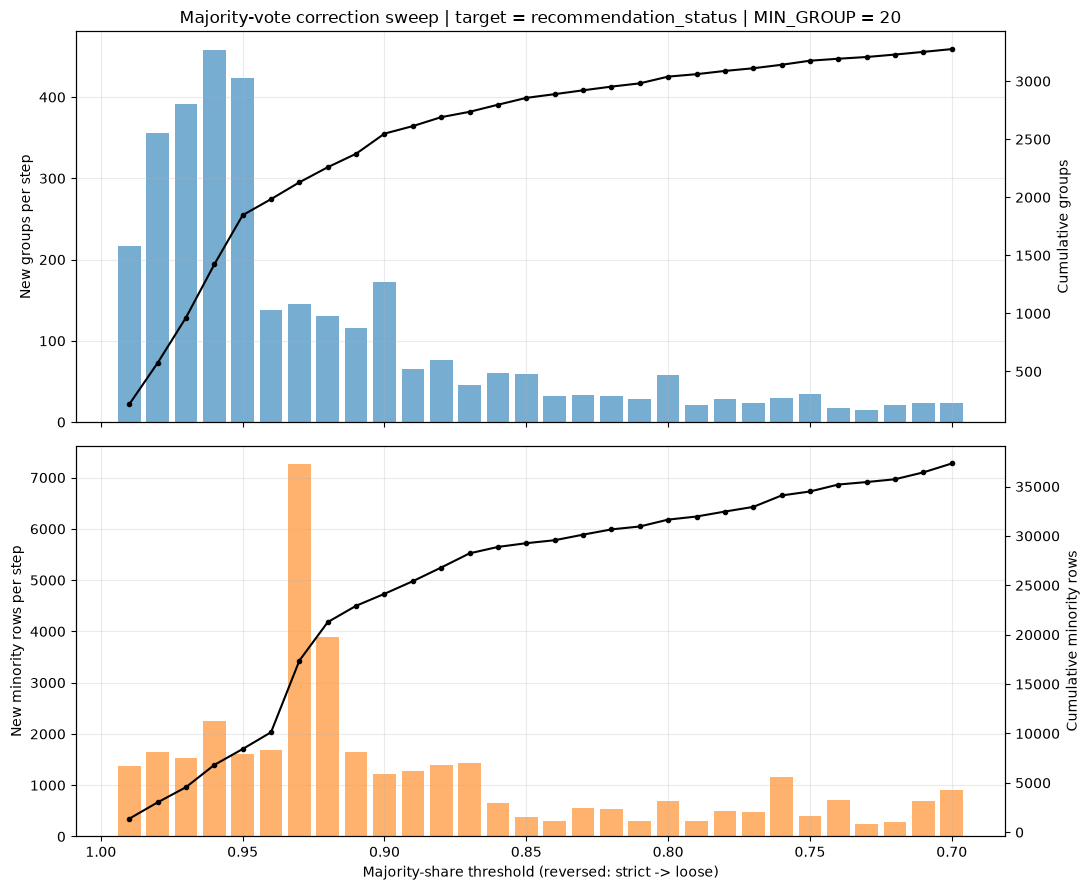

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Only conflict groups can ever be corrected (share == 1 has no minority rows)
conf = groups.loc[groups["majority_share"] < 1, ["body", "majority_share", "n_minority"]]
shares = conf["majority_share"].to_numpy()
minor = conf["n_minority"].to_numpy()

# Threshold grid from THR_MAX down to THR_MIN (rounded to avoid float drift)
n_steps = int(round((THR_MAX - THR_MIN) / THR_STEP))
thr_grid = [round(THR_MAX - i * THR_STEP, 6) for i in range(n_steps + 1)]

EPS = 1e-12  # tolerance for float comparison of share >= threshold
rows = []
for t in thr_grid:
    mask = shares >= t - EPS
    rows.append({
        "threshold": t,
        "cum_groups": int(mask.sum()),
        "cum_minority_rows": int(minor[mask].sum()),
    })

sweep = pd.DataFrame(rows)
sweep["new_groups"] = sweep["cum_groups"].diff().fillna(sweep["cum_groups"]).astype(int)
sweep["new_minority_rows"] = sweep["cum_minority_rows"].diff().fillna(sweep["cum_minority_rows"]).astype(int)
sweep["cum_pct_of_labeled_train"] = (100 * sweep["cum_minority_rows"] / n_train_labeled).round(3)
sweep = sweep[["threshold", "new_groups", "cum_groups",
               "new_minority_rows", "cum_minority_rows", "cum_pct_of_labeled_train"]]

display(sweep)

# ---- Two-panel plot: top = groups, bottom = rows; bars = per-step gain, line = cumulative ----
fig, (ax_g, ax_r) = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
width = THR_STEP * 0.8

def panel(ax, new_col, cum_col, ylabel_new, ylabel_cum, color):
    ax.bar(sweep["threshold"], sweep[new_col], width=width, color=color, alpha=0.6, label=ylabel_new)
    ax.set_ylabel(ylabel_new)
    ax2 = ax.twinx()
    ax2.plot(sweep["threshold"], sweep[cum_col], color="black", marker="o", ms=3, label=ylabel_cum)
    ax2.set_ylabel(ylabel_cum)
    ax.grid(True, alpha=0.25)
    return ax2

panel(ax_g, "new_groups", "cum_groups", "New groups per step", "Cumulative groups", "tab:blue")
panel(ax_r, "new_minority_rows", "cum_minority_rows", "New minority rows per step", "Cumulative minority rows", "tab:orange")

ax_g.set_title(f"Majority-vote correction sweep | target = {TARGET} | MIN_GROUP = {MIN_GROUP}")
ax_r.set_xlabel("Majority-share threshold (reversed: strict -> loose)")
ax_g.invert_xaxis()  # shared x, so both panels are reversed

if SELECTED_THR is not None:
    for ax in (ax_g, ax_r):
        ax.axvline(SELECTED_THR, color="red", linestyle="--", linewidth=1.5)

fig.tight_layout()
fig.savefig(REPORTS / f"label_correction_{TARGET}_sweep.png", dpi=180, bbox_inches="tight")
sweep.to_csv(REPORTS / f"label_correction_{TARGET}_sweep.csv", index=False)
plt.show()

## using Kneedle for finding the approximated best threshold

,threshold,new_groups,cum_groups,new_minority_rows,cum_minority_rows,cum_pct_of_labeled_train
0,0.950,1846,1846,8428,8428,0.229
1,0.945,66,1912,612,9040,0.246
2,0.940,72,1984,1084,10124,0.275
3,0.935,76,2060,392,10516,0.286
4,0.930,69,2129,6867,17383,0.472
5,0.925,70,2199,3383,20766,0.564
6,0.920,60,2259,510,21276,0.578
7,0.915,48,2307,481,21757,0.591
8,0.910,68,2375,1172,22929,0.623
9,0.905,73,2448,558,23487,0.638


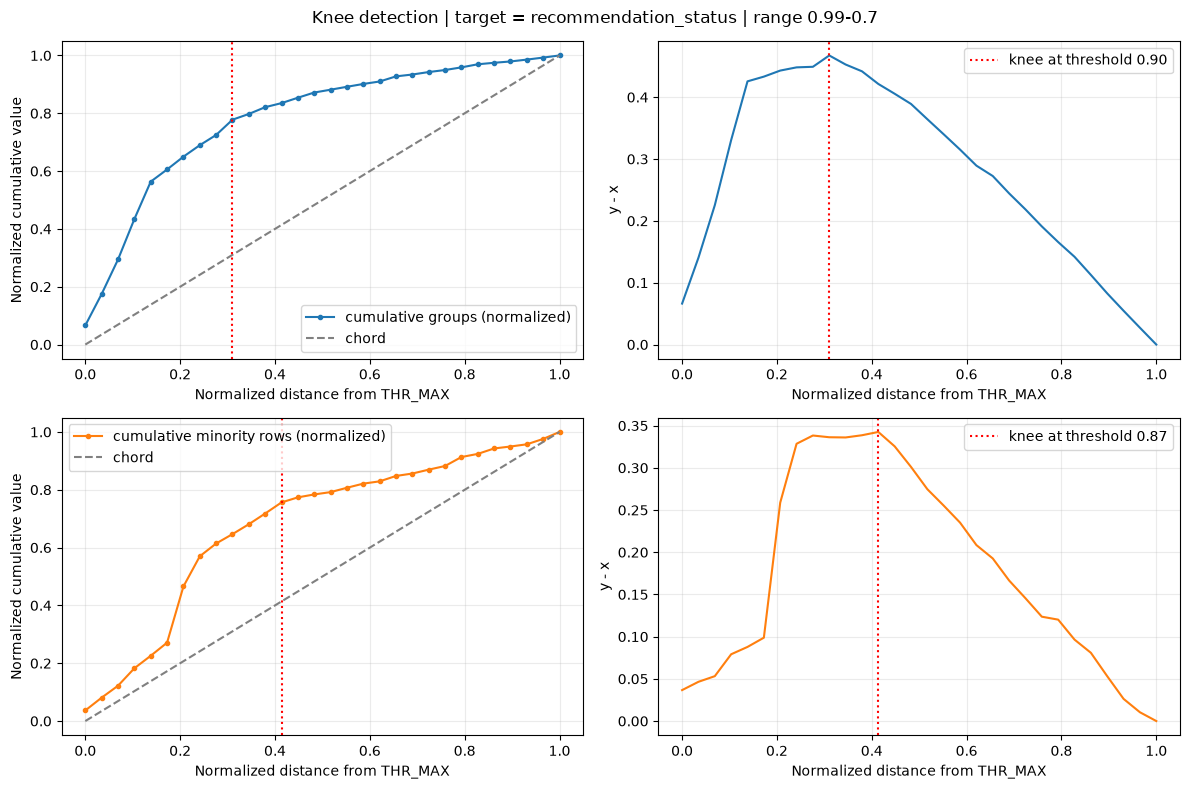

,THR_MIN,knee_cum_groups,knee_cum_minority_rows
0,0.70,0.90,0.87
1,0.75,0.90,0.91
2,0.80,0.95,0.92
3,0.85,0.95,0.92


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def sweep_table(thr_max, thr_min, step):
    # Same logic as step 2, wrapped so it can run on different grids
    n = int(round((thr_max - thr_min) / step))
    grid = [round(thr_max - i * step, 6) for i in range(n + 1)]
    rows = []
    for t in grid:
        m = shares >= t - EPS
        rows.append({"threshold": t,
                     "cum_groups": int(m.sum()),
                     "cum_minority_rows": int(minor[m].sum())})
    sw = pd.DataFrame(rows)
    sw["new_groups"] = sw["cum_groups"].diff().fillna(sw["cum_groups"]).astype(int)
    sw["new_minority_rows"] = sw["cum_minority_rows"].diff().fillna(sw["cum_minority_rows"]).astype(int)
    sw["cum_pct_of_labeled_train"] = (100 * sw["cum_minority_rows"] / n_train_labeled).round(3)
    return sw

def kneedle(sw, col):
    # Kneedle core: normalize both axes to [0, 1]; for a concave increasing curve
    # the knee is where the curve is farthest above the diagonal (y - x is maximal)
    t = sw["threshold"].to_numpy()
    x = (t[0] - t) / (t[0] - t[-1])
    y = sw[col].to_numpy() / sw[col].iloc[-1]
    d = y - x
    i = int(d.argmax())
    return x, y, d, i

# 1) Fine grid inside the candidate range
fine = sweep_table(0.95, 0.90, 0.005)
display(fine[["threshold", "new_groups", "cum_groups",
              "new_minority_rows", "cum_minority_rows", "cum_pct_of_labeled_train"]])

# 2) Normalized cumulative curves + difference curve on the wide range
wide_sw = sweep_table(THR_MAX, THR_MIN, THR_STEP)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for r, (col, name, color) in enumerate([("cum_groups", "groups", "tab:blue"),
                                        ("cum_minority_rows", "minority rows", "tab:orange")]):
    x, y, d, i = kneedle(wide_sw, col)
    thr_knee = wide_sw["threshold"].iloc[i]
    ax = axes[r, 0]
    ax.plot(x, y, color=color, marker="o", ms=3, label=f"cumulative {name} (normalized)")
    ax.plot([0, 1], [0, 1], "--", color="gray", label="chord")
    ax.axvline(x[i], color="red", linestyle=":")
    ax.set(xlabel="Normalized distance from THR_MAX", ylabel="Normalized cumulative value")
    ax.legend(); ax.grid(True, alpha=0.25)
    ax = axes[r, 1]
    ax.plot(x, d, color=color)
    ax.axvline(x[i], color="red", linestyle=":", label=f"knee at threshold {thr_knee:.2f}")
    ax.set(xlabel="Normalized distance from THR_MAX", ylabel="y - x")
    ax.legend(); ax.grid(True, alpha=0.25)
fig.suptitle(f"Knee detection | target = {TARGET} | range {THR_MAX}-{THR_MIN}")
fig.tight_layout()
fig.savefig(REPORTS / f"label_correction_{TARGET}_knee.png", dpi=180, bbox_inches="tight")
plt.show()

# 3) Sensitivity: does the knee move when THR_MIN changes?
sens = []
for tmin in [0.70, 0.75, 0.80, 0.85]:
    sw = sweep_table(THR_MAX, tmin, THR_STEP)
    row = {"THR_MIN": tmin}
    for col in ["cum_groups", "cum_minority_rows"]:
        _, _, _, i = kneedle(sw, col)
        row[f"knee_{col}"] = sw["threshold"].iloc[i]
    sens.append(row)
display(pd.DataFrame(sens))

# Human feedback Auditing for choosing best threshold

In [12]:
import re
import numpy as np
import pandas as pd
from IPython.display import display, HTML, clear_output

CANDIDATES = [0.94, 0.93, 0.92, 0.91]
BAND_WIDTH = 0.01
OUT_DIR = REPORTS / f"label_correction_{TARGET}_bands"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Reading aid only (not a correction rule): flags bodies that look hedged or mixed
HEDGE_RE = re.compile(r"معمولی|بد نیست|بد نبود|بدک نیست|متوسط|قابل قبول|نه خوب|نسبتا|نسبتاً|ولی|اما|فقط|می‌شد|میشد|کاش")

show_cols = [c for c in ["body", "n_labeled", *count_cols, "majority_label", "majority_share",
                         "second_label", "second_ratio", "n_minority"] if c in groups.columns]

def band_table(t):
    m = (groups["majority_share"] >= t - EPS) & (groups["majority_share"] < t + BAND_WIDTH - EPS)
    df = (groups.loc[m, show_cols]
          .sort_values(["n_minority", "body"], ascending=[False, True])   # body breaks ties deterministically
          .reset_index(drop=True))
    df["hedge_hint"] = df["body"].str.contains(HEDGE_RE)
    df["view"] = ""
    df.loc[:N_TOP - 1, "view"] = "top"
    rest = np.arange(N_TOP, len(df))
    pick = np.random.default_rng(SPLIT_SEED).choice(rest, size=min(N_RANDOM, len(rest)), replace=False)
    df.loc[pick, "view"] = "random"
    return df

def band_summary(t, df):
    row = {"threshold": t, "groups": len(df), "minority_rows": int(df["n_minority"].sum()),
           "hedge_hint_groups": int(df["hedge_hint"].sum())}
    for c in count_cols:   # minority rows per label = rows whose label differs from the group's majority
        lab = c[2:]
        row[f"minority_rows_{lab}"] = int(df.loc[df["majority_label"] != lab, c].sum())
    for lab in label_cols:
        row[f"groups_majority_{lab}"] = int((df["majority_label"] == lab).sum())
    return row

tables, summaries = {}, []
sweep_idx = sweep.set_index("threshold")
for t in CANDIDATES:
    df = band_table(t)
    # Consistency with the step-2 sweep
    assert len(df) == sweep_idx.loc[t, "new_groups"], (t, len(df), sweep_idx.loc[t, "new_groups"])
    assert df["n_minority"].sum() == sweep_idx.loc[t, "new_minority_rows"], t
    df.to_csv(OUT_DIR / f"band_{t:.2f}.csv", index=False, encoding="utf-8-sig")
    tables[t] = df
    summaries.append(band_summary(t, df))

band_sum = pd.DataFrame(summaries)
band_sum.to_csv(OUT_DIR / "band_summary.csv", index=False, encoding="utf-8-sig")
print("Saved to:", OUT_DIR)
display(band_sum)

# ---- Interactive dropdown (needs ipywidgets) ----
def html_table(df):
    return (
        "<div style='max-height:520px; overflow:auto; direction:ltr;'>"
        "<style>"
        "table { border-collapse: separate; border-spacing: 0; }"
        "thead th {"
        "   position: sticky;"
        "   top: 0;"
        "   z-index: 10;"
        "   background: #e8edf3;"
        "   color: #222;"
        "   box-shadow: 0 1px 2px rgba(0,0,0,0.15);"
        "}"
        "</style>"
        + df.to_html(index=False, float_format=lambda x: f"{x:.4f}")
        + "</div>"
    )

try:
    import ipywidgets as widgets
    dd = widgets.Dropdown(options=[(f"{t:.2f}", t) for t in CANDIDATES], description="Band:")
    out = widgets.Output()

    def render(t):
        with out:
            clear_output(wait=True)
            display(HTML(f"<b>Groups newly added at threshold {t:.2f} "
                         f"(share in [{t:.2f}, {t + BAND_WIDTH:.2f})): {len(tables[t])}</b>"))
            display(HTML(html_table(tables[t])))

    dd.observe(lambda ch: render(ch["new"]), names="value")
    display(dd, out)
    render(dd.value)
except ImportError:
    print("ipywidgets is not installed. Run `uv pip install ipywidgets` (or pip), or open the CSV files.")
    for t in CANDIDATES:
        print(f"\n=== Band {t:.2f} (top {N_TOP} + {N_RANDOM} random) ===")
        display(tables[t][tables[t]["view"] != ""])

Saved to: /home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/reports/label_correction_recommendation_status_bands


,threshold,groups,minority_rows,hedge_hint_groups,minority_rows_no_idea,minority_rows_not_recommended,minority_rows_recommended,groups_majority_no_idea,groups_majority_not_recommended,groups_majority_recommended
0,0.94,138,1696,3,1544,136,16,1,8,129
1,0.93,145,7259,4,6789,438,32,0,10,135
2,0.92,130,3893,6,3633,242,18,0,7,123
3,0.91,116,1653,6,1541,89,23,1,6,109


Dropdown(description='Band:', options=(('0.94', 0.94), ('0.93', 0.93), ('0.92', 0.92), ('0.91', 0.91)), value=…

Output()

### save the HTML Table

In [13]:

import json
import html as html_lib

# Output directory
HTML_DIR = ROOT / "artifacts" / "Step1_label_correction" / "recommendation_status"
HTML_DIR.mkdir(parents=True, exist_ok=True)

HTML_PATH = HTML_DIR / "label_correction_bands.html"

# Convert all tables to HTML-compatible records
table_data = {
    f"{t:.2f}": tables[t].to_dict(orient="records")
    for t in CANDIDATES
}

# Embed data directly into the HTML file
embedded_data = json.dumps(
    table_data,
    ensure_ascii=False,
    default=str
).replace("</", "<\\/")

html_content = f"""<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">

<title>Label Correction - Recommendation Status</title>

<style>
    body {{
        font-family: Arial, sans-serif;
        margin: 24px;
        color: #222;
        background: #fff;
    }}

    .controls {{
        margin-bottom: 16px;
        display: flex;
        align-items: center;
        gap: 12px;
    }}

    select {{
        padding: 7px 12px;
        font-size: 14px;
        border: 1px solid #bbb;
        border-radius: 5px;
        background: white;
        cursor: pointer;
    }}

    .table-info {{
        margin-bottom: 10px;
        font-weight: bold;
        font-size: 14px;
    }}

    .table-container {{
        max-height: 520px;
        overflow: auto;
        direction: ltr;
        border: 1px solid #ddd;
        border-radius: 5px;
    }}

    table {{
        border-collapse: separate;
        border-spacing: 0;
        width: max-content;
        min-width: 100%;
        font-size: 13px;
        white-space: nowrap;
    }}

    th, td {{
        padding: 8px 10px;
        border-bottom: 1px solid #ddd;
        border-right: 1px solid #eee;
        text-align: left;
    }}

    thead th {{
        position: sticky;
        top: 0;
        z-index: 10;
        background: #e8edf3;
        color: #222;
        box-shadow: 0 1px 2px rgba(0,0,0,0.15);
    }}

    tbody tr:nth-child(even) {{
        background: #f7f9fb;
    }}

    tbody tr:hover {{
        background: #eaf2ff;
    }}
</style>
</head>

<body>

<h2>Label Correction - Recommendation Status</h2>

<div class="controls">
    <label for="threshold">Threshold:</label>
    <select id="threshold"></select>
</div>

<div class="table-info" id="table-info"></div>

<div class="table-container">
    <table id="data-table">
        <thead></thead>
        <tbody></tbody>
    </table>
</div>

<script>
const tableData = {embedded_data};

const dropdown = document.getElementById("threshold");
const tableHead = document.querySelector("#data-table thead");
const tableBody = document.querySelector("#data-table tbody");
const tableInfo = document.getElementById("table-info");

// Populate dropdown
Object.keys(tableData).forEach(threshold => {{
    const option = document.createElement("option");
    option.value = threshold;
    option.textContent = threshold;
    dropdown.appendChild(option);
}});

// Render selected table
function renderTable(threshold) {{
    const rows = tableData[threshold];

    tableHead.innerHTML = "";
    tableBody.innerHTML = "";

    if (!rows.length) {{
        tableInfo.textContent = `Threshold ${{threshold}}: No groups found`;
        return;
    }}

    const columns = Object.keys(rows[0]);

    // Render header
    const headerRow = document.createElement("tr");

    columns.forEach(column => {{
        const th = document.createElement("th");
        th.textContent = column;
        headerRow.appendChild(th);
    }});

    tableHead.appendChild(headerRow);

    // Render body
    rows.forEach(row => {{
        const tr = document.createElement("tr");

        columns.forEach(column => {{
            const td = document.createElement("td");
            const value = row[column];

            td.textContent =
                typeof value === "number" && Number.isFinite(value)
                    ? value.toFixed(4)
                    : value ?? "";

            tr.appendChild(td);
        }});

        tableBody.appendChild(tr);
    }});

    tableInfo.textContent =
        `Groups newly added at threshold ${{threshold}} ` +
        `(share in [${{threshold}}, ${{(Number(threshold) + {BAND_WIDTH}).toFixed(2)}})): ${{rows.length}}`;
}}

// Dropdown interaction
dropdown.addEventListener("change", () => {{
    renderTable(dropdown.value);
}});

// Initial rendering
renderTable(dropdown.value);
</script>

</body>
</html>
"""

# Save standalone HTML
HTML_PATH.write_text(html_content, encoding="utf-8")

print("HTML saved successfully:")
print(HTML_PATH)


HTML saved successfully:
/home/alireza/AI-Bootcamp/Project-3-digikala-review/digikala-review-transformer/artifacts/Step1_label_correction/recommendation_status/label_correction_bands.html


# Final Selection for threshold (majority ratio band): `0.932`